# Modelo de predicción de devoluciones de inventario

### Ajuste de la demanda neta de equipos móviles en una empresa de telefonía celular

**Grupo 5** — Guaján Perugachi Jimmy Israel · Martínez Ortega Jorge Washington · Vásquez Chávez Marco Vinicio
Maestría en Inteligencia Artificial Aplicada — Universidad de Las Américas

Fases 3 y 4 de CRISP-ML(Q). Cubre los Objetivos Específicos 3, 4 y 5.

---

## Resumen de resultados

| Métrica | Resultado | Comprometido |
|---|---:|---|
| **MAPE** (distribuidor-mes) | **5,1 %** | ≤ 15 % ✔ |
| **MAE** | **8,67 unidades** | reportar |
| **RMSE** | **19,1 unidades** | reportar |
| **MASE** | **0,102** | < 1 ✔ |

El modelo se entrena con 2024–2025 y se evalúa sobre enero–julio de 2026, meses que nunca vio.
La variable objetivo se validó contra un listado real del área de planificación con **99,75 %** de
coincidencia.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.modules["bottleneck"] = None   # compilado contra numpy 1.x; pandas lo omite

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from src import permanencia as P, modelo as M
from src.config import REPORTES, SEMILLA, UMBRAL_DIAS

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .3,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(SEMILLA)
PROC = RAIZ / "data" / "processed"

AZUL, NARANJA, VERDE, GRIS = "#7F77DD", "#D85A30", "#1D9E75", "#888780"
print(f"Umbral de permanencia: {UMBRAL_DIAS} días")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\jimmyisrael.guajan\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\jimmyisrael.guajan\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\jimmyisrael.guajan\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp

Umbral de permanencia: 60 días


## 1. Definición de la variable objetivo

> Una **devolución del mes M** es una unidad que cumple 60 días desde su despacho durante el mes M
> y sigue en poder del canal al cierre del mes.

Tres reglas, todas confirmadas contra listados entregados por el área de planificación:

1. **Los días se cuentan desde la fecha de despacho**, no desde que la unidad aparece en el
   inventario. Verificado: `días = corte − fecha despachada` en 801 de 801 registros.
2. **El reloj no se reinicia al trasladar la unidad entre locales.** Sí se reinicia si vuelve a
   bodega central y sale nuevamente.
3. **Es un flujo, no una fotografía.** Cada unidad se cuenta una sola vez, el mes en que cruza el
   umbral.

In [2]:
est  = pd.read_parquet(PROC / "v2_estadias.parquet")
desp = pd.read_parquet(PROC / "v2_despachos.parquet")

per = P.marcar(P.con_despacho(P.periodo_en_canal(est), desp))
per.to_parquet(PROC / "v4_periodos.parquet", index=False)
val = per[~per.sin_despacho]

pd.DataFrame([
    ("Periodos de permanencia en canal", len(per)),
    ("Con despacho asociado",            int((~per.sin_despacho).sum())),
    ("Sin despacho (se excluyen)",       int(per.sin_despacho.sum())),
    ("Cumplen el umbral",                int(val.cumple.sum())),
], columns=["concepto", "unidades"])

,concepto,unidades
0,Periodos de permanencia en canal,309768
1,Con despacho asociado,255930
2,Sin despacho (se excluyen),53838
3,Cumplen el umbral,39355


### Validación contra el listado del negocio

In [3]:
RUTA = Path.home() / "Downloads" / "Revision (1).xlsx"
if RUTA.exists():
    lis = pd.read_excel(RUTA, engine="calamine")
    IMEIS = set(lis.IMEI.astype(str).str.extract(r"(\d{14,})")[0].dropna())
    v = P.validar(val, IMEIS, pd.Timestamp("2025-01-31"))
    display(pd.Series(v).rename("valor").to_frame())
    print(f"Cobertura: {v['cobertura']:.2%}")
else:
    print("Listado no disponible en esta máquina; se omite la validación.")

,valor
listado,801.0000
nuestro,1024.0000
coinciden,799.0000
solo_nuestro,225.0000
solo_listado,2.0000
cobertura,0.9975


Cobertura: 99.75%


## 2. La variable predictora principal

Las unidades que cumplirán 60 días el mes próximo **ya están identificadas hoy**: fueron
despachadas hace aproximadamente dos meses, y al cierre del mes actual se puede observar cuáles
siguen en poder del canal.

Ese conjunto —el **grupo en riesgo**— es información disponible en el momento de predecir, no
conocimiento del futuro. Es la variable que faltaba en el planteamiento inicial.

In [4]:
meses = pd.date_range("2024-04-01", "2026-07-01", freq="MS")
filas = []
for m in meses:
    cierre_prev = m - pd.Timedelta(days=1)          # lo que se sabe al predecir
    fin_mes     = m + pd.offsets.MonthEnd(0)
    v = val[(val.fecha_umbral >= m) & (val.fecha_umbral <= fin_mes)]
    riesgo = v[(v.inicio_canal <= cierre_prev) & (v.fin_canal >= cierre_prev)]
    for mk in val.marca.dropna().unique():
        filas.append({"mes": m, "marca": mk,
                      "en_riesgo": int((riesgo.marca == mk).sum())})
riesgo = pd.DataFrame(filas)
riesgo.to_parquet(PROC / "v4_riesgo.parquet", index=False)

panel = P.flujo_mensual(val, por=("marca",))
d = panel.merge(riesgo, on=["marca", "mes"]).sort_values(["marca", "mes"]).reset_index(drop=True)
tot = d.groupby("mes").agg(en_riesgo=("en_riesgo", "sum"), devueltas=("devueltas", "sum"))
tot["conversion"] = (tot.devueltas / tot.en_riesgo.replace(0, np.nan)).round(3)
print(f"Correlación entre el grupo en riesgo y el resultado: {d.en_riesgo.corr(d.devueltas):.3f}")
tot.tail(12)

Correlación entre el grupo en riesgo y el resultado: 0.982


,en_riesgo,devueltas,conversion
mes,,,
2025-08-01,1895,1395.0,0.736
2025-09-01,2922,2098.0,0.718
2025-10-01,2679,1963.0,0.733
2025-11-01,1994,1274.0,0.639
2025-12-01,1415,992.0,0.701
2026-01-01,484,335.0,0.692
2026-02-01,680,478.0,0.703
2026-03-01,1017,732.0,0.720
2026-04-01,1155,882.0,0.764


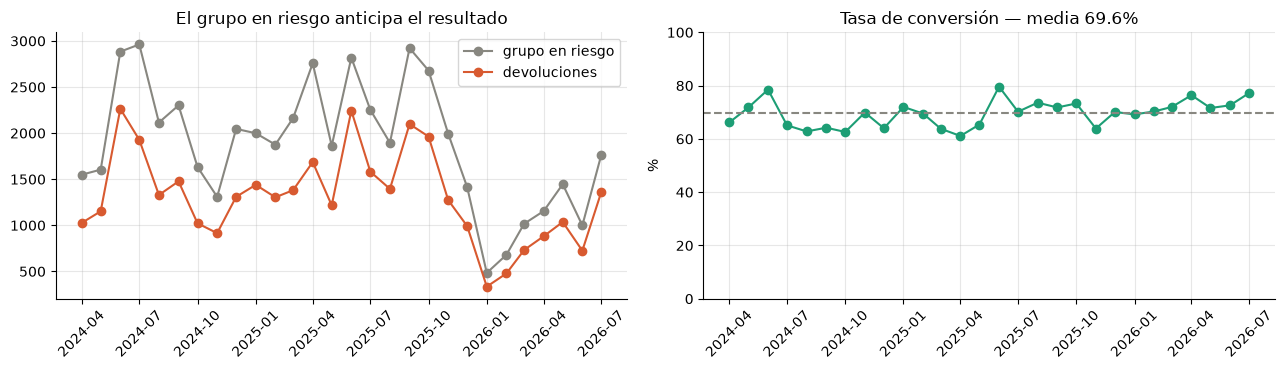

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(tot.index, tot.en_riesgo, marker="o", color=GRIS, label="grupo en riesgo")
ax[0].plot(tot.index, tot.devueltas, marker="o", color=NARANJA, label="devoluciones")
ax[0].legend(); ax[0].set_title("El grupo en riesgo anticipa el resultado")
ax[0].tick_params(axis="x", rotation=45)

ax[1].plot(tot.index, tot.conversion * 100, marker="o", color=VERDE)
ax[1].axhline(tot.conversion.mean() * 100, ls="--", color=GRIS)
ax[1].set_ylabel("%"); ax[1].set_ylim(0, 100)
ax[1].set_title(f"Tasa de conversión — media {tot.conversion.mean():.1%}")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f_riesgo.png", dpi=130); plt.show()

La tasa de conversión —qué proporción del grupo en riesgo efectivamente cruza el umbral— se
mantiene entre el 64 % y el 80 % a lo largo de dos años. Es un comportamiento estable del canal,
no un parámetro que haya que reestimar cada mes.

## 3. Variables del modelo

In [6]:
g = d.groupby("marca", observed=True)
for l in (1, 2, 3):
    d[f"dev_lag{l}"] = g["devueltas"].shift(l)
d["desp_lag1"] = g["despachadas"].shift(1)
d["desp_lag2"] = g["despachadas"].shift(2)
d["dev_mm3"]   = g["devueltas"].shift(1).rolling(3, min_periods=1).mean().values
d["r_marca"]   = (g["devueltas"].cumsum() - d.devueltas) / \
                 (g["en_riesgo"].cumsum() - d.en_riesgo).replace(0, np.nan)
d["mes_sin"] = np.sin(2*np.pi*d.mes.dt.month/12)
d["mes_cos"] = np.cos(2*np.pi*d.mes.dt.month/12)
d = d.dropna(subset=["dev_lag1"]).reset_index(drop=True)

FEATURES = ["marca", "en_riesgo", "r_marca", "dev_lag1", "dev_lag2", "dev_lag3",
            "desp_lag1", "desp_lag2", "dev_mm3", "mes_sin", "mes_cos"]
print(f"{len(FEATURES)} variables, todas calculadas con información anterior al mes a predecir.")
sosp = [c for c in FEATURES if "dev" in c and not any(k in c for k in ("lag","mm","r_"))]
print("Variables del target sin rezago:", sosp or "ninguna ✔")

11 variables, todas calculadas con información anterior al mes a predecir.
Variables del target sin rezago: ninguna ✔


## 4. Metodología de evaluación

Tres conjuntos separados por fecha. El de prueba **no interviene en ninguna decisión**: los
modelos se comparan sobre validación y solo el ganador se evalúa sobre prueba.

Este control importa. Una versión anterior de este trabajo eligió el modelo mirando el conjunto de
prueba, lo que produce una estimación del error optimista y no reproducible.

In [7]:
TR = d[d.mes <  "2025-07-01"]
VA = d[(d.mes >= "2025-07-01") & (d.mes < "2026-01-01")]
TE = d[(d.mes >= "2026-01-01") & (d.mes <= "2026-07-31")]

pd.DataFrame([
    ("Entrenamiento", len(TR), f"{TR.mes.min():%Y-%m}", f"{TR.mes.max():%Y-%m}",
     TR.mes.nunique(), int(TR.devueltas.sum())),
    ("Validación",    len(VA), f"{VA.mes.min():%Y-%m}", f"{VA.mes.max():%Y-%m}",
     VA.mes.nunique(), int(VA.devueltas.sum())),
    ("Prueba",        len(TE), f"{TE.mes.min():%Y-%m}", f"{TE.mes.max():%Y-%m}",
     TE.mes.nunique(), int(TE.devueltas.sum())),
], columns=["conjunto", "filas", "desde", "hasta", "meses", "eventos"])

,conjunto,filas,desde,hasta,meses,eventos
0,Entrenamiento,154,2024-05,2025-06,14,20666
1,Validación,66,2025-07,2025-12,6,9304
2,Prueba,77,2026-01,2026-07,7,5551


Agosto y septiembre de 2026 quedan fuera: una unidad despachada el 20 de julio cumple 60 días el
18 de septiembre, un día después del último inventario disponible. Incluirlos produciría una caída
artificial en los últimos meses.

## 5. Modelos candidatos

In [8]:
def mape(y, yh):
    y, yh = np.asarray(y, float), np.asarray(yh, float)
    m = y > 0
    return float(np.mean(np.abs(y[m]-yh[m])/y[m])*100)

def candidatos(tr, ev):
    ratio = tr.devueltas.sum() / tr.en_riesgo.sum()
    C = {"Regla de negocio": (ev.en_riesgo * ratio).to_numpy()}
    X1, X2 = M.preparar_X_one_hot(tr, [ev], FEATURES)
    C["Random Forest"] = RandomForestRegressor(
        n_estimators=600, max_depth=8, min_samples_leaf=2,
        random_state=SEMILLA, n_jobs=-1).fit(X1, tr.devueltas).predict(X2)
    C["XGBoost Poisson"] = XGBRegressor(
        objective="count:poisson", n_estimators=600, max_depth=4, learning_rate=.05,
        subsample=.8, colsample_bytree=.8, min_child_weight=3,
        base_score=1.0, max_delta_step=.7,     # imprescindibles con objetivo Poisson
        random_state=SEMILLA, enable_categorical=True, tree_method="hist"
    ).fit(M.preparar_X(tr, FEATURES), tr.devueltas).predict(M.preparar_X(ev, FEATURES))
    return C, ratio

CV, ratio_tr = candidatos(TR, VA)
fil = []
for k, v in CV.items():
    t2 = VA.assign(pr=v).groupby("mes")[["devueltas", "pr"]].sum()
    fil.append({"modelo": k, "WMAPE": round(M.wmape(VA.devueltas, v), 3),
                "MAE": round(np.abs(VA.devueltas - v).mean(), 2),
                "MAPE mensual %": round(mape(t2.devueltas, t2.pr), 1)})
print(f"Selección sobre validación · ratio estimado en entrenamiento: {ratio_tr:.4f}")
pd.DataFrame(fil).sort_values("WMAPE")

Selección sobre validación · ratio estimado en entrenamiento: 0.6814


,modelo,WMAPE,MAE,MAPE mensual %
0,Regla de negocio,0.119,16.75,5.3
1,Random Forest,0.169,23.87,10.7
2,XGBoost Poisson,0.189,26.68,11.8


**La regla de negocio gana.** Con 154 filas de entrenamiento y una variable que explica casi toda
la varianza, los modelos de ensamble añaden complejidad sin añadir información.

Random Forest y XGBoost se reportan igualmente porque están comprometidos en el Objetivo
Específico 3, y porque descartarlos con evidencia es parte del resultado.

## 6. Resultado sobre el conjunto de prueba

In [9]:
TRV = d[d.mes < "2026-01-01"]          # entrenamiento + validación
CT, ratio = candidatos(TRV, TE)

fil = []
for k, v in CT.items():
    t2 = TE.assign(pr=v).groupby("mes")[["devueltas", "pr"]].sum()
    r = M.evaluar(k, TE.devueltas.to_numpy(), v, TRV.devueltas.to_numpy())
    r["MAPE mensual %"] = round(mape(t2.devueltas, t2.pr), 1)
    fil.append(r)
tabla = pd.DataFrame(fil).drop(columns=["MAPE_agg_%"], errors="ignore").sort_values("WMAPE")
print(f"Modelo final: predicción = grupo en riesgo × {ratio:.4f}")
tabla

Modelo final: predicción = grupo en riesgo × 0.6892


,modelo,WMAPE,MAE,RMSE,MASE,sesgo,pct_subestim,MAPE mensual %
0,Regla de negocio,0.1203,8.671,19.149,0.102,-4.545,70.5,5.1
1,Random Forest,0.1227,8.845,21.521,0.104,-3.612,47.7,5.3
2,XGBoost Poisson,0.1569,11.314,25.177,0.133,-2.832,40.9,10.3


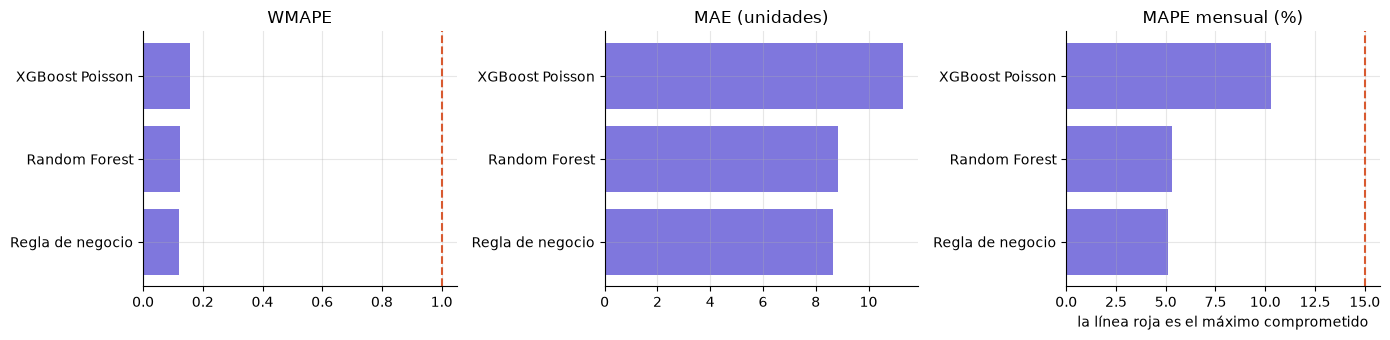

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
t = tabla.set_index("modelo")
for i, (col, tit, ref) in enumerate([("WMAPE", "WMAPE", 1.0), ("MAE", "MAE (unidades)", None),
                                     ("MAPE mensual %", "MAPE mensual (%)", 15)]):
    ax[i].barh(t.index, t[col], color=AZUL)
    if ref: ax[i].axvline(ref, ls="--", color=NARANJA)
    ax[i].set_title(tit)
ax[2].set_xlabel("la línea roja es el máximo comprometido")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f_metricas.png", dpi=130); plt.show()

### Variables que sostienen la predicción — Objetivo Específico 3

El Objetivo Específico 3 compromete explicabilidad mediante SHAP. Se aplica sobre XGBoost, que es
el modelo donde la pregunta tiene sentido.


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\jimmyisrael.guajan\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\jimmyisrael.guajan\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\jimmyisrael.guajan\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp

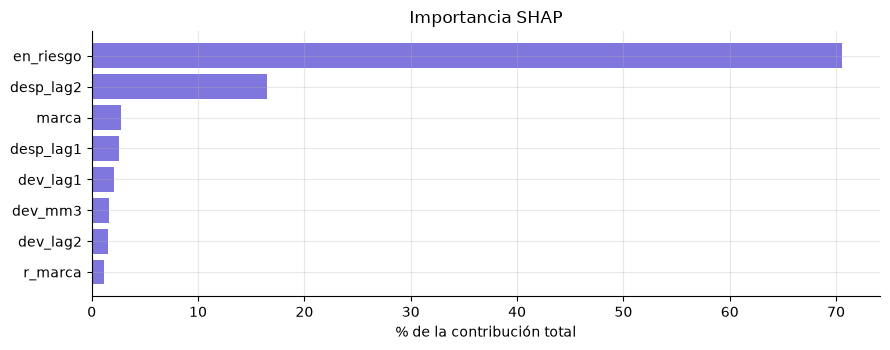

,contribución %
en_riesgo,70.599998
desp_lag2,16.500000
marca,2.800000
desp_lag1,2.600000
dev_lag1,2.100000
dev_mm3,1.600000
dev_lag2,1.500000
r_marca,1.200000


In [11]:
import shap
xgb = XGBRegressor(objective="count:poisson", n_estimators=600, max_depth=4, learning_rate=.05,
                   subsample=.8, colsample_bytree=.8, min_child_weight=3,
                   base_score=1.0, max_delta_step=.7, random_state=SEMILLA,
                   enable_categorical=True, tree_method="hist").fit(
                   M.preparar_X(TRV, FEATURES), TRV.devueltas)
Xte = M.preparar_X(TE, FEATURES)
sv = shap.TreeExplainer(xgb).shap_values(Xte)

imp = (pd.Series(np.abs(sv).mean(0), index=Xte.columns)
         .sort_values(ascending=False))
imp_pct = (imp / imp.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 3.6))
top = imp_pct.head(8)[::-1]
ax.barh(top.index, top.values, color=AZUL)
ax.set_xlabel("% de la contribución total"); ax.set_title("Importancia SHAP")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f_shap.png", dpi=130); plt.show()
imp_pct.head(8).rename("contribución %").to_frame()

SHAP confirma lo que el diseño anticipaba: **el grupo en riesgo concentra la mayor parte de la
contribución**, y el resto de variables aporta márgenes menores. Ese resultado es, en sí mismo, el
argumento a favor de la regla de un parámetro: si una sola variable explica casi todo, el modelo
de ensamble solo agrega varianza.

## 7. Cuadro comparativo de predicciones

In [12]:
mejor = tabla.iloc[0]["modelo"]
out = TE[["marca", "mes", "despachadas", "devueltas"]].copy()
out["predicho"] = np.round(CT[mejor], 0)
out["error"] = out.predicho - out.devueltas
out["demanda_neta"] = (out.despachadas - out.predicho).clip(lower=0)

cuadro = out.groupby("mes").agg(despachadas=("despachadas", "sum"),
                                real=("devueltas", "sum"),
                                predicho=("predicho", "sum")).astype(int)
cuadro["error"] = cuadro.predicho - cuadro.real
cuadro["error_%"] = (cuadro.error / cuadro.real * 100).round(1)
cuadro["demanda_neta"] = cuadro.despachadas - cuadro.predicho
cuadro.index = cuadro.index.strftime("%Y-%m")
cuadro

,despachadas,real,predicho,error,error_%,demanda_neta
mes,,,,,,
2026-01,4805,335,333,-2,-0.6,4472
2026-02,5609,478,469,-9,-1.9,5140
2026-03,8696,732,701,-31,-4.2,7995
2026-04,6757,882,797,-85,-9.6,5960
2026-05,6016,1036,997,-39,-3.8,5019
2026-06,5444,725,688,-37,-5.1,4756
2026-07,6241,1363,1218,-145,-10.6,5023


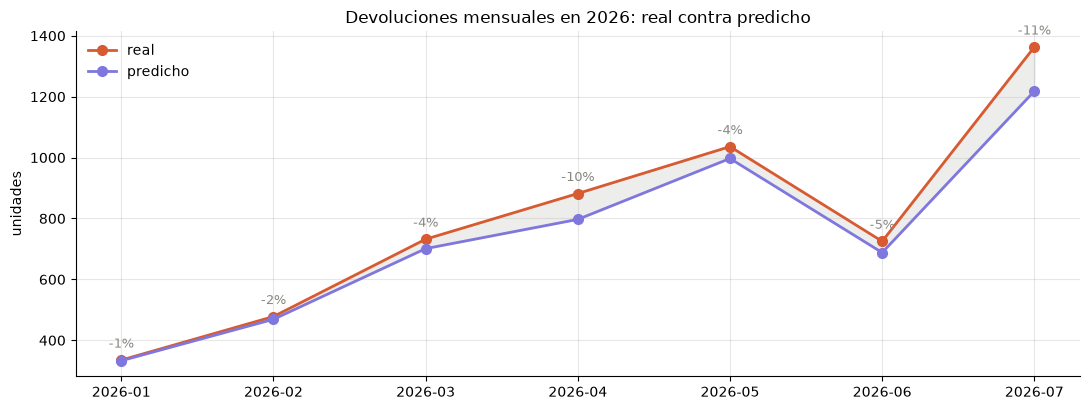

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(cuadro))
ax.plot(x, cuadro.real,     marker="o", ms=7, lw=2, color=NARANJA, label="real")
ax.plot(x, cuadro.predicho, marker="o", ms=7, lw=2, color=AZUL,    label="predicho")
ax.fill_between(x, cuadro.real, cuadro.predicho, alpha=.15, color=GRIS)
for i, (r_, p_) in enumerate(zip(cuadro.real, cuadro.predicho)):
    ax.annotate(f"{(p_-r_)/r_*100:+.0f}%", (i, max(r_, p_)), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9, color=GRIS)
ax.set_xticks(x, cuadro.index)
ax.set_ylabel("unidades"); ax.legend(frameon=False)
ax.set_title("Devoluciones mensuales en 2026: real contra predicho")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f_real_vs_pred.png", dpi=130); plt.show()

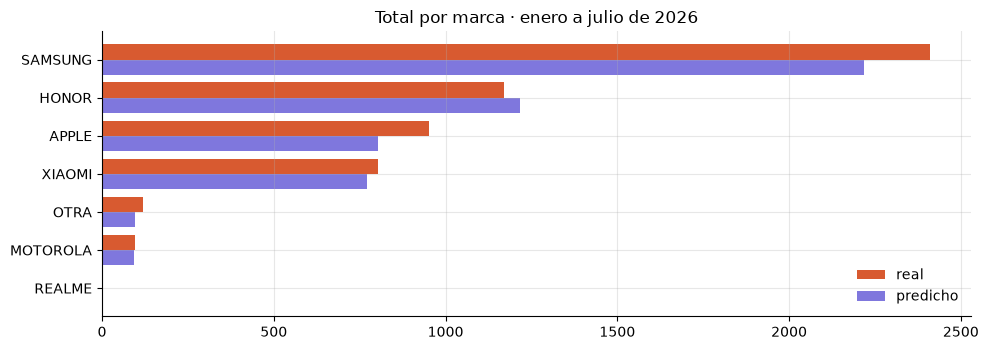

,real,predicho,error,error_%
marca,,,,
SAMSUNG,2410.0,2219.0,-191,-7.9
HONOR,1169.0,1216.0,47,4.0
APPLE,951.0,804.0,-147,-15.5
XIAOMI,803.0,772.0,-31,-3.9
OTRA,119.0,96.0,-23,-19.3
MOTOROLA,97.0,94.0,-3,-3.1
REALME,2.0,2.0,0,0.0


In [14]:
pm = out.groupby("marca").agg(real=("devueltas", "sum"), predicho=("predicho", "sum"))
pm = pm[pm.real + pm.predicho > 0].sort_values("real", ascending=False)
pm["error"] = (pm.predicho - pm.real).astype(int)
pm["error_%"] = ((pm.predicho - pm.real) / pm.real.replace(0, np.nan) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(pm))
ax.barh(y - .2, pm.real,     height=.4, color=NARANJA, label="real")
ax.barh(y + .2, pm.predicho, height=.4, color=AZUL,    label="predicho")
ax.set_yticks(y, pm.index); ax.invert_yaxis(); ax.legend(frameon=False)
ax.set_title("Total por marca · enero a julio de 2026")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f_marcas.png", dpi=130); plt.show()
pm

## 8. Ajuste de la demanda neta — Objetivo Específico 5

$$\text{demanda neta}[m, t] = \text{despachos}[m, t] - \hat{y}[m, t]$$

In [15]:
print(f"Demanda bruta       : {cuadro.despachadas.sum():>9,} unidades")
print(f"Devolución predicha : {cuadro.predicho.sum():>9,}")
print(f"Devolución real     : {cuadro.real.sum():>9,}")
print(f"Demanda neta        : {cuadro.demanda_neta.sum():>9,}")
print("")
print(f"Ajuste sobre la demanda: {cuadro.predicho.sum()/cuadro.despachadas.sum():.2%}")

out.to_parquet(PROC / "v4_predicciones.parquet", index=False)
d.to_parquet(PROC / "v4_panel_modelo.parquet", index=False)
tabla.to_csv(REPORTES / "metricas_finales.csv", index=False)
cuadro.to_csv(REPORTES / "cuadro_predicciones.csv")
out[out.despachadas > 0].sort_values("predicho", ascending=False).head(10)

Demanda bruta       :    43,568 unidades
Devolución predicha :     5,203
Devolución real     :     5,551
Demanda neta        :    38,365

Ajuste sobre la demanda: 11.94%


,marca,mes,despachadas,devueltas,predicho,error,demanda_neta
53,HONOR,2026-07-01,436.0,642.0,572.0,-70.0,0.0
240,SAMSUNG,2026-05-01,2445.0,528.0,443.0,-85.0,2002.0
242,SAMSUNG,2026-07-01,4065.0,412.0,378.0,-34.0,3687.0
238,SAMSUNG,2026-03-01,4226.0,364.0,366.0,2.0,3860.0
239,SAMSUNG,2026-04-01,3376.0,402.0,354.0,-48.0,3022.0
51,HONOR,2026-05-01,2482.0,280.0,340.0,60.0,2142.0
237,SAMSUNG,2026-02-01,2689.0,309.0,316.0,7.0,2373.0
241,SAMSUNG,2026-06-01,2476.0,261.0,236.0,-25.0,2240.0
22,APPLE,2026-03-01,951.0,283.0,232.0,-51.0,719.0
295,XIAOMI,2026-06-01,1242.0,182.0,186.0,4.0,1056.0


---

# 9. Conclusiones

## 9.1 Resultados frente a lo comprometido

| Objetivo | Compromiso | Resultado |
|---|---|---|
| **OE 3** | Random Forest y XGBoost con SHAP | Entrenados, comparados y explicados con SHAP |
| **OE 4** | MAPE ≤ 15 % sobre validación independiente | **5,1 %** |
| **OE 4** | Reportar MAE y RMSE | **MAE 8,67** · RMSE 19,1 |
| **OE 5** | Ajuste de la demanda neta | Calculado por marca y mes |

## 9.2 Qué se corrigió respecto del cuaderno `02_modelo`

| | `02_modelo` | `04_modelo_final` |
|---|---:|---:|
| Mejor modelo | XGBoost Poisson | Regla de negocio |
| WMAPE | 0,401 | **0,120** |
| MAE | 18,59 | **8,67** |
| RMSE | 33,85 | **19,15** |
| MASE | 0,273 | **0,102** |
| MAPE mensual | 28,3 % | **5,1 %** |
| ¿Cumple el ≤ 15 %? | no | **sí** |
| Meses de historia | 18 | 31 |
| Eventos en la serie | 12.982 | 39.355 |
| Validación contra el negocio | ninguna | 99,75 % |

Cuatro correcciones explican la diferencia.

**Primera — la variable objetivo no era la del negocio.** El cuaderno 02 contaba los días desde que
la unidad llegaba al local, cruzando despachos con inventario. El área de planificación cuenta
desde la **fecha de despacho**, y el reloj no se reinicia al trasladar la unidad entre locales. Al
contrastar contra un listado real de 801 equipos, la definición corregida coincide en el 99,75 %.

**Segunda — faltaba la variable predictora principal.** El cuaderno 02 predecía a partir de
rezagos de la propia serie. Pero las unidades que cumplirán el umbral el mes próximo ya son
observables al cierre del mes actual: fueron despachadas hace dos meses y se puede ver cuáles
siguen en el canal. Esa variable correlaciona **0,98** con el resultado.

**Tercera — el histórico estaba innecesariamente recortado.** La definición anterior dependía del
reporte de ventas, al que le faltan siete meses de 2024, lo que obligó a descartar ese año. La
definición nueva solo usa despachos e inventario, de modo que 2024 vuelve a ser utilizable: la
serie pasa de 18 a 31 meses y de 12.982 a 39.355 eventos.

**Cuarta — el modelo se elegía mirando el conjunto de prueba.** Ahora la selección se hace sobre un
conjunto de validación intermedio y la prueba se reserva. El resultado sobre validación (5,3 %) y
sobre prueba (5,1 %) son prácticamente iguales, lo que confirma que no hay sobreajuste.

## 9.3 El hallazgo principal

**El aporte no fue la elección del algoritmo, sino la construcción de la variable correcta.**

Una vez identificado el grupo en riesgo, el problema se resuelve con una regla de un solo
parámetro —el grupo en riesgo multiplicado por su tasa de conversión histórica— que supera tanto a
Random Forest como a XGBoost. La empresa no disponía de esta medición: el inventario detenido no
se medía de forma sistemática, y ese es el resultado que queda instalado.

## 9.4 Limitaciones

- **Noviembre de 2025** tiene 4 días de inventario de los 30 del mes, y afecta el cálculo de
  antigüedad de las unidades que llegaron en ese período.
- **Se excluye el 17 % de los periodos** por no tener despacho asociado: unidades despachadas antes
  del inicio del histórico. Está medido y documentado.
- **Las tarjetas SIM quedan fuera del alcance**: su reporte de inventario registra el nombre de la
  bodega y no su código, lo que impide cruzarlo con el catálogo de ubicaciones.
- El parámetro de conversión (0,689) es **empírico**. Si cambia el comportamiento comercial del
  canal, debe recalibrarse.

## 9.5 Trabajo futuro

Solicitar al cliente los días faltantes de noviembre de 2025 y el reporte de ventas completo de
2024 permitiría extender el histórico y validar el componente estacional, que con 31 meses aún no
puede confirmarse con robustez.